https://www.kaggle.com/code/abdallahsaadelgendy/diabetes-prediction-eda-preprocessing-models/notebook

In [13]:
## import libraries

# data handling
import pandas as pd
import numpy as np

# Data viz
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [32]:
df_raw=pd.read_csv('data/mental_health_survey.csv')
print(f'Shape   : {df_raw.shape}')
print(f'Columns : {df_raw.columns.tolist()}')
df_raw.head(3)

Shape   : (1259, 27)
Columns : ['Timestamp', 'Age', 'Gender', 'Country', 'state', 'self_employed', 'family_history', 'treatment', 'work_interfere', 'no_employees', 'remote_work', 'tech_company', 'benefits', 'care_options', 'wellness_program', 'seek_help', 'anonymity', 'leave', 'mental_health_consequence', 'phys_health_consequence', 'coworkers', 'supervisor', 'mental_health_interview', 'phys_health_interview', 'mental_vs_physical', 'obs_consequence', 'comments']


,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN


In [33]:
# Column dictionary
col_dict = {
    'Age'                      : 'Respondent age',
    'Gender'                   : 'Gender (messy — needs cleaning)',
    'Country'                  : 'Country of employment',
    'self_employed'            : 'Is the respondent self-employed?',
    'family_history'           : 'Family history of mental illness',
    'treatment'                : '🎯 TARGET — Has sought mental health treatment?',
    'work_interfere'           : 'Does mental health interfere with work?',
    'no_employees'             : 'Company size (number of employees)',
    'remote_work'              : 'Works remotely?',
    'tech_company'             : 'Works at a tech company?',
    'benefits'                 : 'Does employer provide mental health benefits?',
    'care_options'             : 'Aware of mental health care options at work?',
    'wellness_program'         : 'Employer has wellness program?',
    'seek_help'                : 'Employer provides resources to seek help?',
    'anonymity'                : 'Anonymity protected if using mental health resources?',
    'leave'                    : 'How easy to take mental health leave?',
    'mental_health_consequence': 'Fear of negative consequences for mental health disclosure?',
    'phys_health_consequence'  : 'Fear of negative consequences for physical health disclosure?',
    'coworkers'                : 'Comfortable discussing mental health with coworkers?',
    'supervisor'               : 'Comfortable discussing mental health with supervisor?',
    'mental_health_interview'  : 'Would bring up mental health in job interview?',
    'phys_health_interview'    : 'Would bring up physical health in job interview?',
    'mental_vs_physical'       : 'Employer treats mental health as seriously as physical?',
    'obs_consequence'          : 'Observed negative consequences for mental health disclosure?',
}
print('Column Dictionary:')
for col, desc in col_dict.items():
    print(f'  {col:30s} | {desc}')

Column Dictionary:
  Age                            | Respondent age
  Gender                         | Gender (messy — needs cleaning)
  Country                        | Country of employment
  self_employed                  | Is the respondent self-employed?
  family_history                 | Family history of mental illness
  treatment                      | 🎯 TARGET — Has sought mental health treatment?
  work_interfere                 | Does mental health interfere with work?
  no_employees                   | Company size (number of employees)
  remote_work                    | Works remotely?
  tech_company                   | Works at a tech company?
  benefits                       | Does employer provide mental health benefits?
  care_options                   | Aware of mental health care options at work?
  wellness_program               | Employer has wellness program?
  seek_help                      | Employer provides resources to seek help?
  anonymity                  

In [34]:
print(df_raw.info())

<class 'pandas.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Timestamp                  1259 non-null   str  
 1   Age                        1259 non-null   int64
 2   Gender                     1259 non-null   str  
 3   Country                    1259 non-null   str  
 4   state                      744 non-null    str  
 5   self_employed              1241 non-null   str  
 6   family_history             1259 non-null   str  
 7   treatment                  1259 non-null   str  
 8   work_interfere             995 non-null    str  
 9   no_employees               1259 non-null   str  
 10  remote_work                1259 non-null   str  
 11  tech_company               1259 non-null   str  
 12  benefits                   1259 non-null   str  
 13  care_options               1259 non-null   str  
 14  wellness_program           1259 non

### Missing values

In [37]:
# --- Detailed Missing Values Summary ---
missing_summary = pd.DataFrame({
    'Missing Count': df_raw.isnull().sum(),
    'Missing Percent (%)': (df_raw.isnull().sum() / len(df_raw)) * 100
})

# Display only columns that contain missing values
missing_only = missing_summary[missing_summary['Missing Count'] > 0]
print(missing_only.sort_values(by='Missing Count', ascending=False))

                Missing Count  Missing Percent (%)
comments                 1095            86.973789
state                     515            40.905481
work_interfere            264            20.969023
self_employed              18             1.429706


### Distributions

      count          mean           std     min   25%   50%   75%  \
Age  1259.0  7.942815e+07  2.818299e+09 -1726.0  27.0  31.0  36.0   

              max  
Age  1.000000e+11  


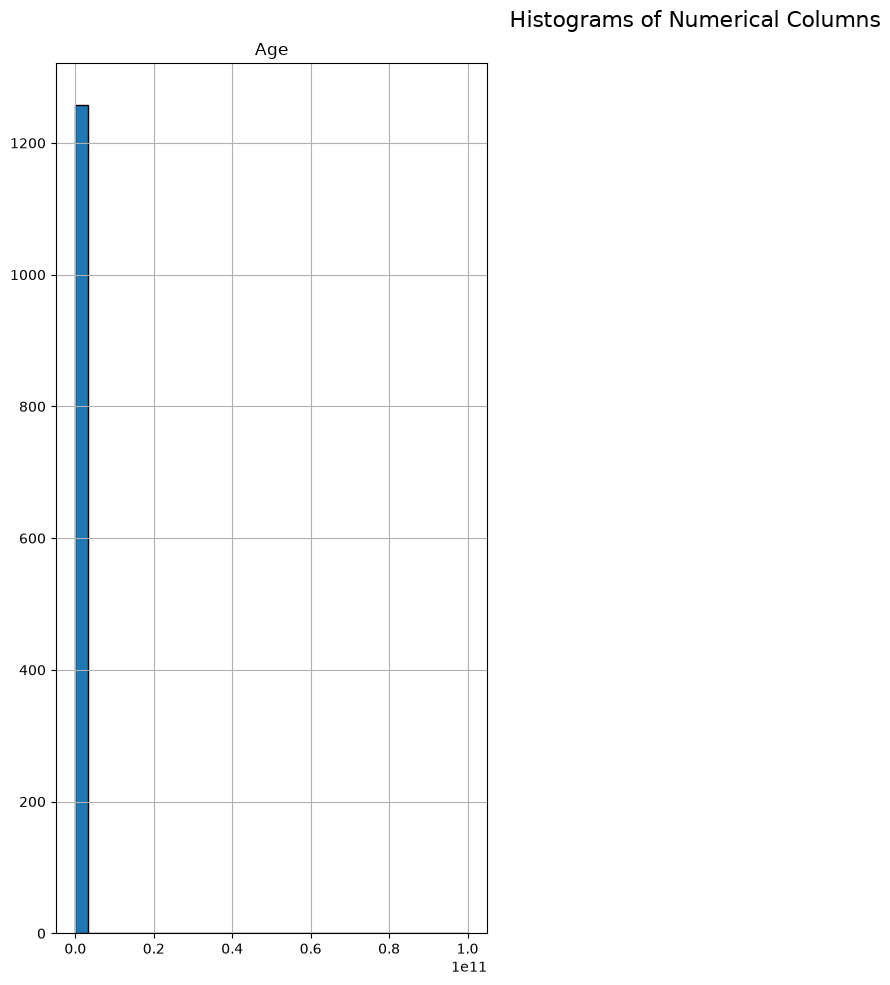

In [44]:
# numerical columns
# Summary statistics (mean, std, min, 25%, 50%, 75%, max)
print(df_raw.describe().T)

# Plot histograms and KDE (Kernel Density Estimate) for all numerical features
num_cols = df_raw.select_dtypes(include=['number']).columns

df_raw[num_cols].hist(bins=30, figsize=(14, 10), layout=(-1, 3), edgecolor='black')
plt.suptitle('Histograms of Numerical Columns', fontsize=16)
plt.tight_layout()
plt.show()

# Boxplots to inspect skewness and outliers
# plt.figure(figsize=(12, 6))
# sns.boxplot(data=df_raw[num_cols])
# plt.xticks(rotation=45)
# plt.title('Boxplot of Numerical Features')
# plt.show()


In [42]:
# Select object and category dtypes
cat_cols = df_raw.select_dtypes(include=['object', 'category']).columns

# Value counts for each categorical column (including NaNs)
for col in cat_cols:
    print(f"\n--- Distribution of '{col}' ---")
    print(df_raw[col].value_counts(dropna=False, normalize=True) * 100)  # Proportions (%)

# Bar plots for categorical features
# for col in cat_cols:
#     plt.figure(figsize=(8, 4))
#     sns.countplot(data=df_raw, x=col, order=df_raw[col].value_counts().index)
#     plt.title(f'Category Frequency: {col}')
#     plt.xticks(rotation=45)
#     plt.tight_layout()
#     plt.show()


--- Distribution of 'Timestamp' ---
Timestamp
2014-08-27 12:31:41    0.158856
2014-08-27 12:37:50    0.158856
2014-08-27 12:43:28    0.158856
2014-08-27 12:44:51    0.158856
2014-08-27 12:54:11    0.158856
                         ...   
2015-09-12 11:17:21    0.079428
2015-09-26 01:07:35    0.079428
2015-11-07 12:36:58    0.079428
2015-11-30 21:25:06    0.079428
2016-02-01 23:04:31    0.079428
Name: proportion, Length: 1246, dtype: float64

--- Distribution of 'Gender' ---
Gender
Male                                              48.848292
male                                              16.362192
Female                                             9.610802
M                                                  9.213662
female                                             4.924543
F                                                  3.018268
m                                                  2.700556
f                                                  1.191422
Make                             

/var/folders/pm/9f068dg15csbjk3w6rp3gplm0000gn/T/ipykernel_82125/808304769.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_raw.select_dtypes(include=['object', 'category']).columns


## SECTION 2 — Data Cleaning

Key challenges: 
- Gender has 49 messy values (Female, F, female, Woman...), 
- Age has outliers (999, -1)
- 264 missing work_interfere values.

In [43]:
df = df_raw.copy()

# ── Clean Gender ─────────────────────────────────────────────
def clean_gender(g):
    if pd.isna(g): return 'Unknown'
    g = str(g).strip().lower()
    if g in ['female','f','woman','femail','cis female','cis-female','female (cis)',
             'femake','female ','feamle','female (trans)','trans woman','trans-female']:
        return 'Female'
    if g in ['male','m','man','cis male','cis man','male (cis)','maile','mal',
             'make','male ','msle','mail','malr','cis-male','male-ish','m|']:
        return 'Male'
    return 'Other/Non-binary'

df['gender_clean'] = df['Gender'].apply(clean_gender)

# ── Clean Age ────────────────────────────────────────────────
df['age_clean'] = df['Age'].copy()
df.loc[df['age_clean'] < 18, 'age_clean'] = np.nan
df.loc[df['age_clean'] > 75, 'age_clean'] = np.nan
df['age_clean'] = df['age_clean'].fillna(df['age_clean'].median())
df['age_clean'] = df['age_clean'].astype(int)

# ── Age groups ───────────────────────────────────────────────
def age_group(a):
    if a < 25:  return '18-24'
    if a < 35:  return '25-34'
    if a < 45:  return '35-44'
    if a < 55:  return '45-54'
    return '55+'

df['age_group'] = df['age_clean'].apply(age_group)

# ── Fill missing work_interfere ──────────────────────────────
df['work_interfere'] = df['work_interfere'].fillna('Unknown')

# ── Fill missing self_employed ───────────────────────────────
df['self_employed'] = df['self_employed'].fillna('No')

# ── Binary target ────────────────────────────────────────────
df['treatment_bin'] = (df['treatment'] == 'Yes').astype(int)

# ── Drop unused columns ──────────────────────────────────────
df = df.drop(columns=['Timestamp','comments','state','Gender','Age'], errors='ignore')

print(f'Clean shape : {df.shape}')
print(f'Missing     : {df.isnull().sum().sum()}')
print(f'\nGender distribution:')
print(df['gender_clean'].value_counts().to_string())
print(f'\nAge stats: mean={df["age_clean"].mean():.1f}, median={df["age_clean"].median():.0f}')
print(f'Treatment rate: {df["treatment_bin"].mean()*100:.1f}%')
df.head(3)


Clean shape : (1259, 26)
Missing     : 0

Gender distribution:
gender_clean
Male                991
Female              250
Other/Non-binary     18

Age stats: mean=32.1, median=31
Treatment rate: 50.6%


,Country,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,...,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,gender_clean,age_clean,age_group,treatment_bin
0,United States,No,No,Yes,Often,6-25,No,Yes,Yes,Not sure,...,Some of them,Yes,No,Maybe,Yes,No,Female,37,35-44,1
1,United States,No,No,No,Rarely,More than 1000,No,No,Don't know,No,...,No,No,No,No,Don't know,No,Male,44,35-44,0
2,Canada,No,No,No,Rarely,6-25,No,Yes,No,No,...,Yes,Yes,Yes,Yes,No,No,Male,32,25-34,0


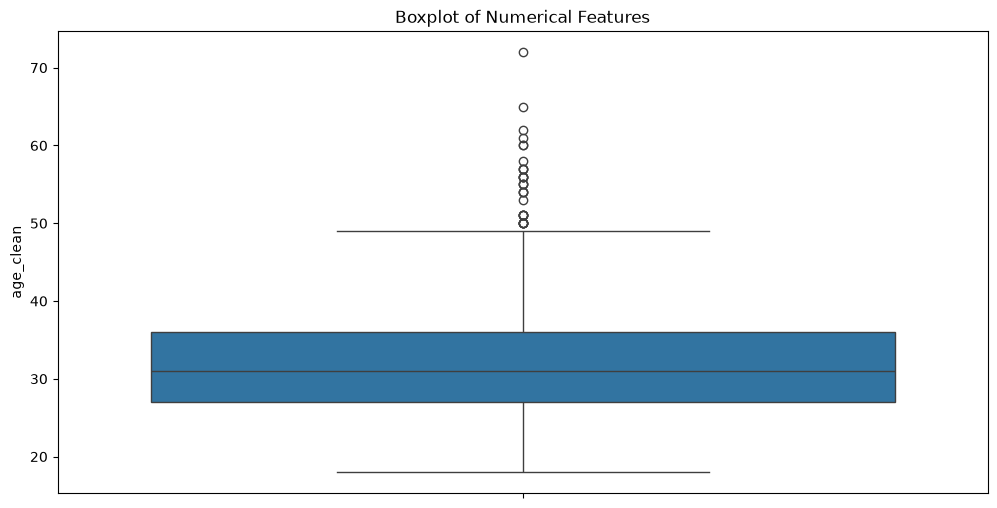

In [47]:
# Boxplots to inspect skewness and outliers
plt.figure(figsize=(12, 6))
sns.boxplot(data=df["age_clean"])
plt.xticks(rotation=45)
plt.title('Boxplot of Numerical Features')
plt.show()

In [49]:
df.head()

,Country,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,...,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,gender_clean,age_clean,age_group,treatment_bin
0,United States,No,No,Yes,Often,6-25,No,Yes,Yes,Not sure,...,Some of them,Yes,No,Maybe,Yes,No,Female,37,35-44,1
1,United States,No,No,No,Rarely,More than 1000,No,No,Don't know,No,...,No,No,No,No,Don't know,No,Male,44,35-44,0
2,Canada,No,No,No,Rarely,6-25,No,Yes,No,No,...,Yes,Yes,Yes,Yes,No,No,Male,32,25-34,0
3,United Kingdom,No,Yes,Yes,Often,26-100,No,Yes,No,Yes,...,Some of them,No,Maybe,Maybe,No,Yes,Male,31,25-34,1
4,United States,No,No,No,Never,100-500,Yes,Yes,Yes,No,...,Some of them,Yes,Yes,Yes,Don't know,No,Male,31,25-34,0


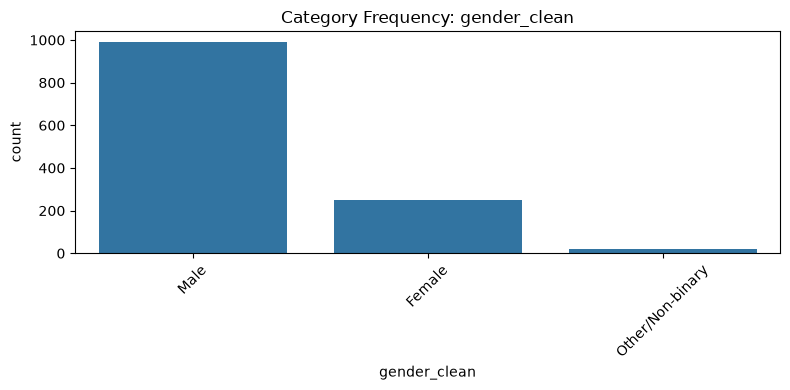

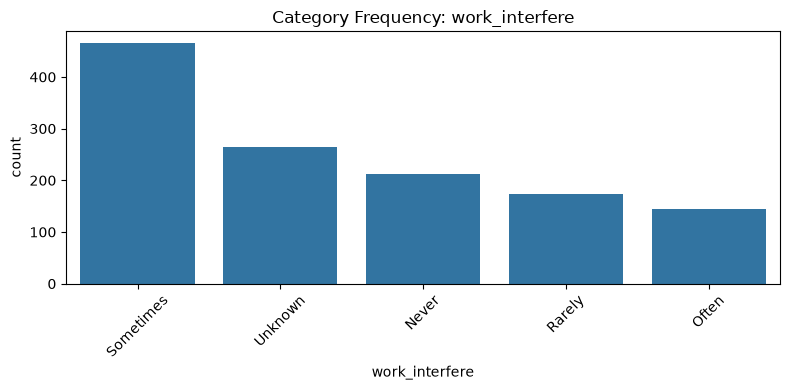

In [50]:
# Bar plots for categorical features
cat_cols_cln = ['gender_clean','work_interfere']
for col in cat_cols_cln:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f'Category Frequency: {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## feature engineering

In [53]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [54]:
# ── Binary encodings ─────────────────────────────────────────
binary_map = {'Yes': 1, 'No': 0}
df['family_history_bin']  = df['family_history'].map(binary_map).fillna(0)
df['remote_work_bin']     = df['remote_work'].map(binary_map).fillna(0)
df['tech_company_bin']    = df['tech_company'].map(binary_map).fillna(0)
df['self_employed_bin']   = df['self_employed'].map(binary_map).fillna(0)
df['obs_consequence_bin'] = df['obs_consequence'].map(binary_map).fillna(0)

# ── Benefits score (0-3: No=0, Don't know=1, Yes=2) ─────────
benefit_map = {'No': 0, "Don't know": 1, 'Yes': 2}
df['benefits_score']         = df['benefits'].map(benefit_map).fillna(1)
df['care_options_score']     = df['care_options'].map({'No':0,'Not sure':1,'Yes':2}).fillna(1)
df['wellness_score']         = df['wellness_program'].map({'No':0,"Don't know":1,'Yes':2}).fillna(1)
df['seek_help_score']        = df['seek_help'].map({'No':0,"Don't know":1,'Yes':2}).fillna(1)
df['anonymity_score']        = df['anonymity'].map({'No':0,"Don't know":1,'Yes':2}).fillna(1)

# ── Composite company support score (0-10) ───────────────────
df['company_support_score'] = (df['benefits_score'] + df['care_options_score'] +
                                df['wellness_score'] + df['seek_help_score'] +
                                df['anonymity_score'])

# ── Work interference encoding ───────────────────────────────
interfere_map = {'Never': 0, 'Rarely': 1, 'Sometimes': 2, 'Often': 3, 'Unknown': 1}
df['work_interfere_enc'] = df['work_interfere'].map(interfere_map).fillna(1)

# ── Leave difficulty encoding ────────────────────────────────
leave_map = {'Very easy': 0, 'Somewhat easy': 1, "Don't know": 2,
             'Somewhat difficult': 3, 'Very difficult': 4}
df['leave_enc'] = df['leave'].map(leave_map).fillna(2)

# ── Consequence fear encoding ────────────────────────────────
consequence_map = {'No': 0, 'Maybe': 1, 'Yes': 2}
df['mh_consequence_enc'] = df['mental_health_consequence'].map(consequence_map).fillna(1)
df['ph_consequence_enc'] = df['phys_health_consequence'].map(consequence_map).fillna(1)

# ── Comfort discussing encoding ──────────────────────────────
comfort_map = {'No': 0, 'Some of them': 1, 'Yes': 2}
df['coworkers_enc']  = df['coworkers'].map(comfort_map).fillna(1)
df['supervisor_enc'] = df['supervisor'].map({'No':0,'Some of them':1,'Yes':2}).fillna(1)

# ── Interview willingness ────────────────────────────────────
interview_map = {'No': 0, 'Maybe': 1, 'Yes': 2}
df['mh_interview_enc'] = df['mental_health_interview'].map(interview_map).fillna(1)
df['ph_interview_enc'] = df['phys_health_interview'].map(interview_map).fillna(1)

# ── Mental vs physical parity ────────────────────────────────
df['mh_parity_enc'] = df['mental_vs_physical'].map({'No':0,"Don't know":1,'Yes':2}).fillna(1)

# ── Company size encoding ────────────────────────────────────
size_map = {'1-5':0,'6-25':1,'26-100':2,'100-500':3,'500-1000':4,'More than 1000':5}
df['company_size_enc'] = df['no_employees'].map(size_map).fillna(2)

# ── Gender encoding ──────────────────────────────────────────
gender_map = {'Male':0,'Female':1,'Other/Non-binary':2}
df['gender_enc'] = df['gender_clean'].map(gender_map).fillna(0)

# ── Country grouping ─────────────────────────────────────────
top_countries = df['Country'].value_counts().head(10).index.tolist()
df['country_group'] = df['Country'].apply(lambda x: x if x in top_countries else 'Other')

le_country = LabelEncoder()
df['country_enc'] = le_country.fit_transform(df['country_group'])

print(f'Total features: {len(df.columns)}')
print('\nCompany support score stats:')
print(df['company_support_score'].describe().round(2).to_string())


Total features: 50

Company support score stats:
count    1259.00
mean        4.48
std         2.64
min         0.00
25%         3.00
50%         4.00
75%         6.00
max        10.00


## Univariate analysis

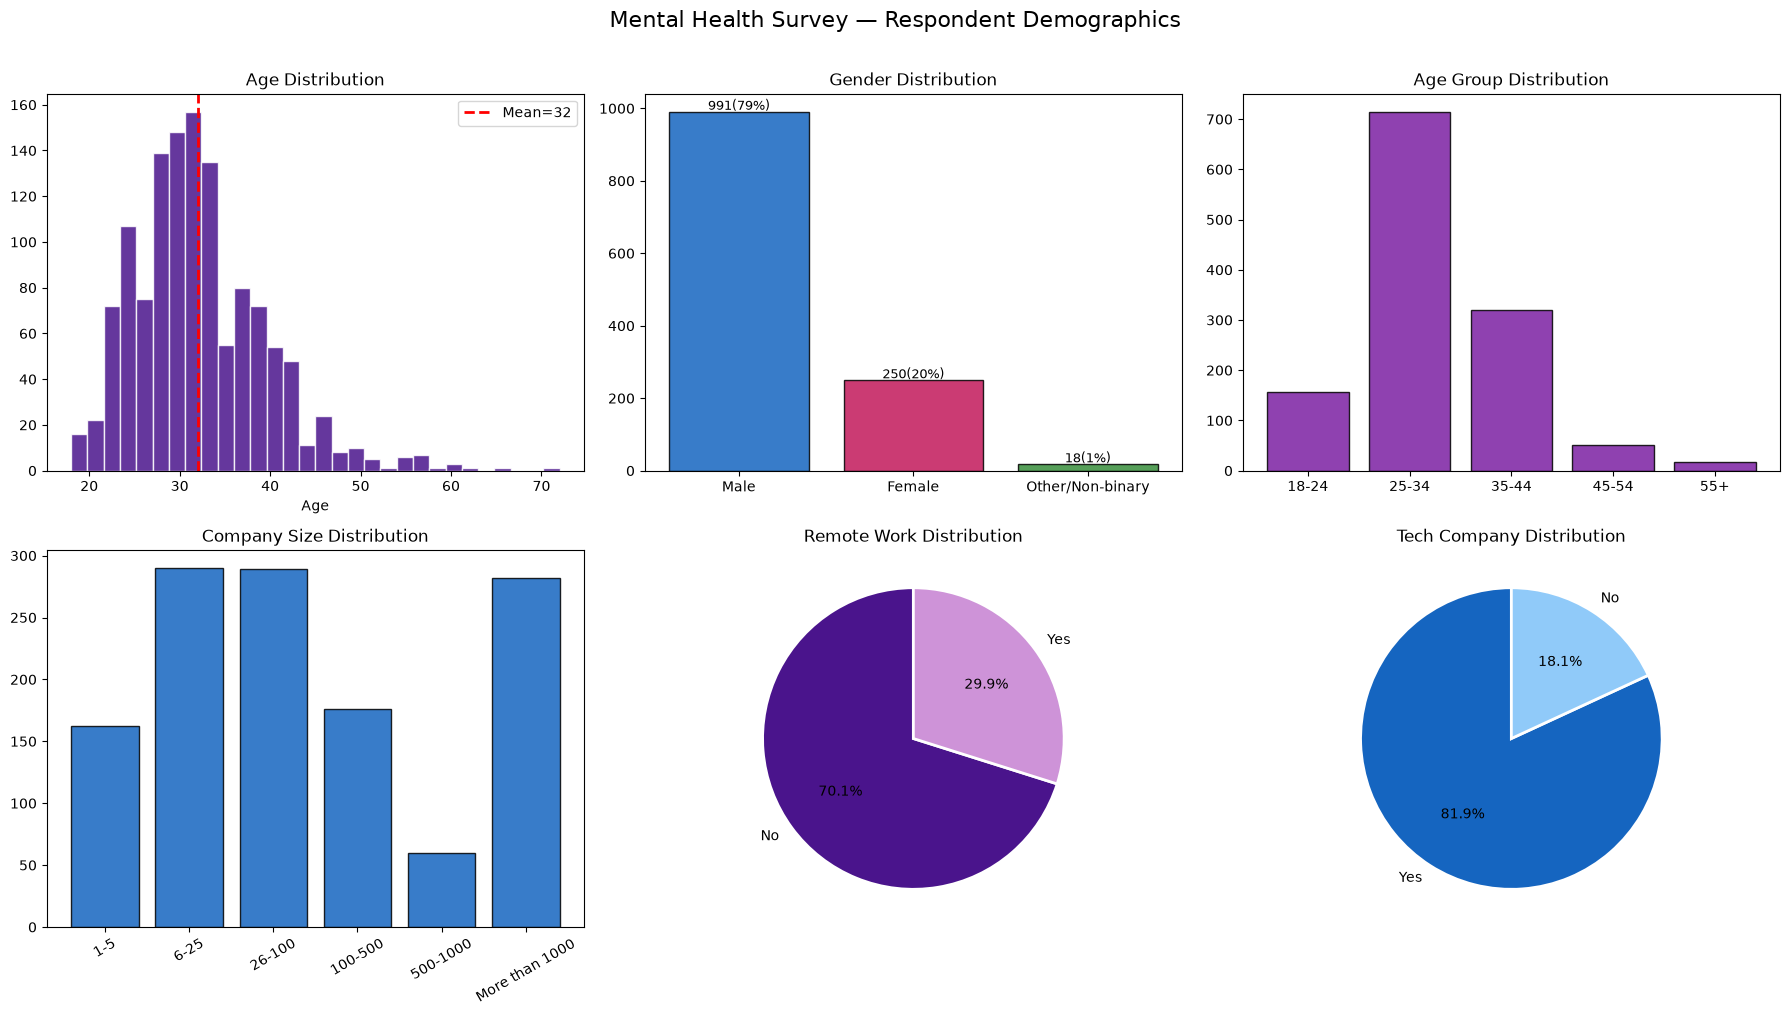

Total respondents : 1,259
Countries covered : 48
Age range         : 18 – 72
Remote workers    : 376 (29.9%)
Tech company      : 1031 (81.9%)


In [55]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Age distribution
axes[0,0].hist(df['age_clean'], bins=30, color='#4a148c', edgecolor='white', alpha=0.85)
axes[0,0].axvline(df['age_clean'].mean(), color='red', linestyle='--', lw=2,
                  label=f'Mean={df["age_clean"].mean():.0f}')
axes[0,0].set_title('Age Distribution'); axes[0,0].set_xlabel('Age'); axes[0,0].legend()

# Gender
gender_counts = df['gender_clean'].value_counts()
axes[0,1].bar(gender_counts.index, gender_counts.values,
              color=['#1565c0','#c2185b','#388e3c'], edgecolor='black', alpha=0.85)
axes[0,1].set_title('Gender Distribution')
for bar, val in zip(axes[0,1].patches, gender_counts.values):
    axes[0,1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
                   f'{val}({val/len(df)*100:.0f}%)', ha='center', fontsize=9)

# Age group
age_counts = df['age_group'].value_counts().reindex(['18-24','25-34','35-44','45-54','55+'])
axes[0,2].bar(age_counts.index, age_counts.values, color='#7b1fa2', edgecolor='black', alpha=0.85)
axes[0,2].set_title('Age Group Distribution')

# Company size
size_order = ['1-5','6-25','26-100','100-500','500-1000','More than 1000']
size_counts = df['no_employees'].value_counts().reindex(size_order)
axes[1,0].bar(size_counts.index, size_counts.values, color='#1565c0', edgecolor='black', alpha=0.85)
axes[1,0].set_title('Company Size Distribution'); axes[1,0].tick_params(axis='x', rotation=30)

# Remote work
remote_counts = df['remote_work'].value_counts()
axes[1,1].pie(remote_counts.values, labels=remote_counts.index,
              colors=['#4a148c','#ce93d8'], autopct='%1.1f%%', startangle=90,
              wedgeprops=dict(edgecolor='white', linewidth=2))
axes[1,1].set_title('Remote Work Distribution')

# Tech company
tech_counts = df['tech_company'].value_counts()
axes[1,2].pie(tech_counts.values, labels=tech_counts.index,
              colors=['#1565c0','#90caf9'], autopct='%1.1f%%', startangle=90,
              wedgeprops=dict(edgecolor='white', linewidth=2))
axes[1,2].set_title('Tech Company Distribution')

plt.suptitle('Mental Health Survey — Respondent Demographics', fontsize=16, y=1.01)
plt.tight_layout(); plt.show()

print(f'Total respondents : {len(df):,}')
print(f'Countries covered : {df["Country"].nunique()}')
print(f'Age range         : {df["age_clean"].min()} – {df["age_clean"].max()}')
print(f'Remote workers    : {df["remote_work_bin"].sum()} ({df["remote_work_bin"].mean()*100:.1f}%)')
print(f'Tech company      : {df["tech_company_bin"].sum()} ({df["tech_company_bin"].mean()*100:.1f}%)')


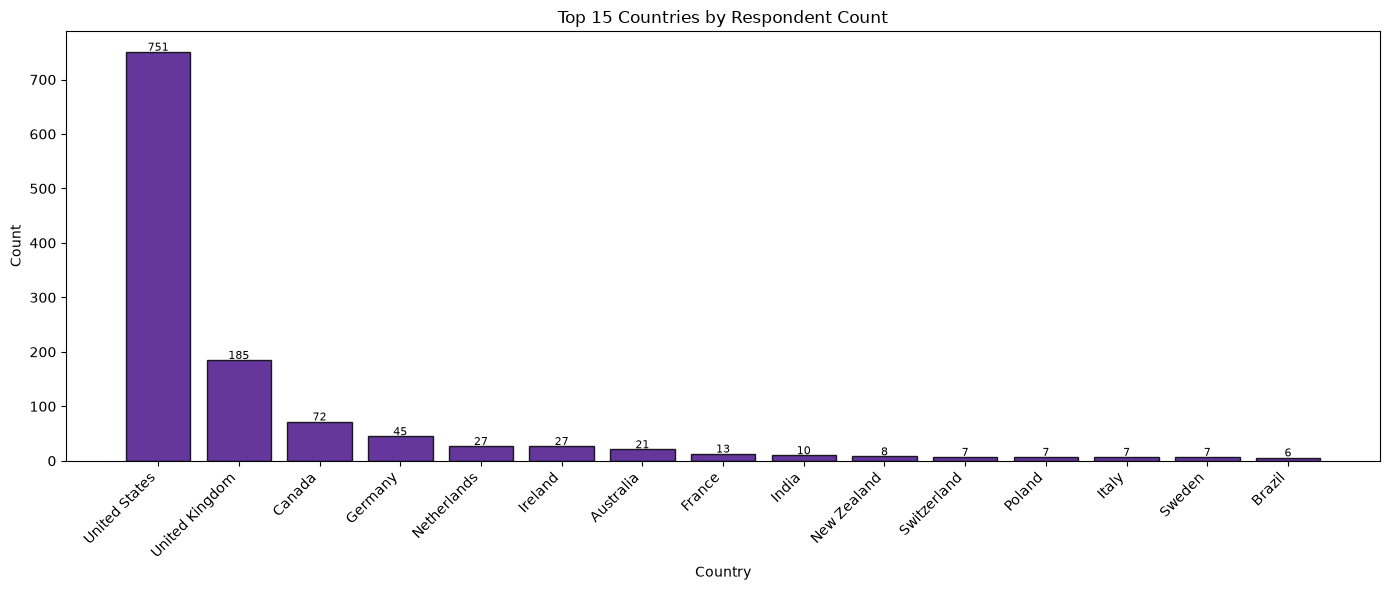

In [56]:
# Top 15 countries
country_counts = df['Country'].value_counts().head(15)
plt.figure(figsize=(14, 6))
bars = plt.bar(country_counts.index, country_counts.values,
               color='#4a148c', edgecolor='black', alpha=0.85)
for bar, val in zip(bars, country_counts.values):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+2,
             str(val), ha='center', fontsize=8)
plt.title('Top 15 Countries by Respondent Count')
plt.xlabel('Country'); plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()

## Treatment Seeking Analysis

Target variable: treatment — Has the respondent sought mental health treatment?
This is our primary prediction target. Understanding who seeks treatment and why is the core research question.

Treatment rate: 637 / 1,259 = 50.6%


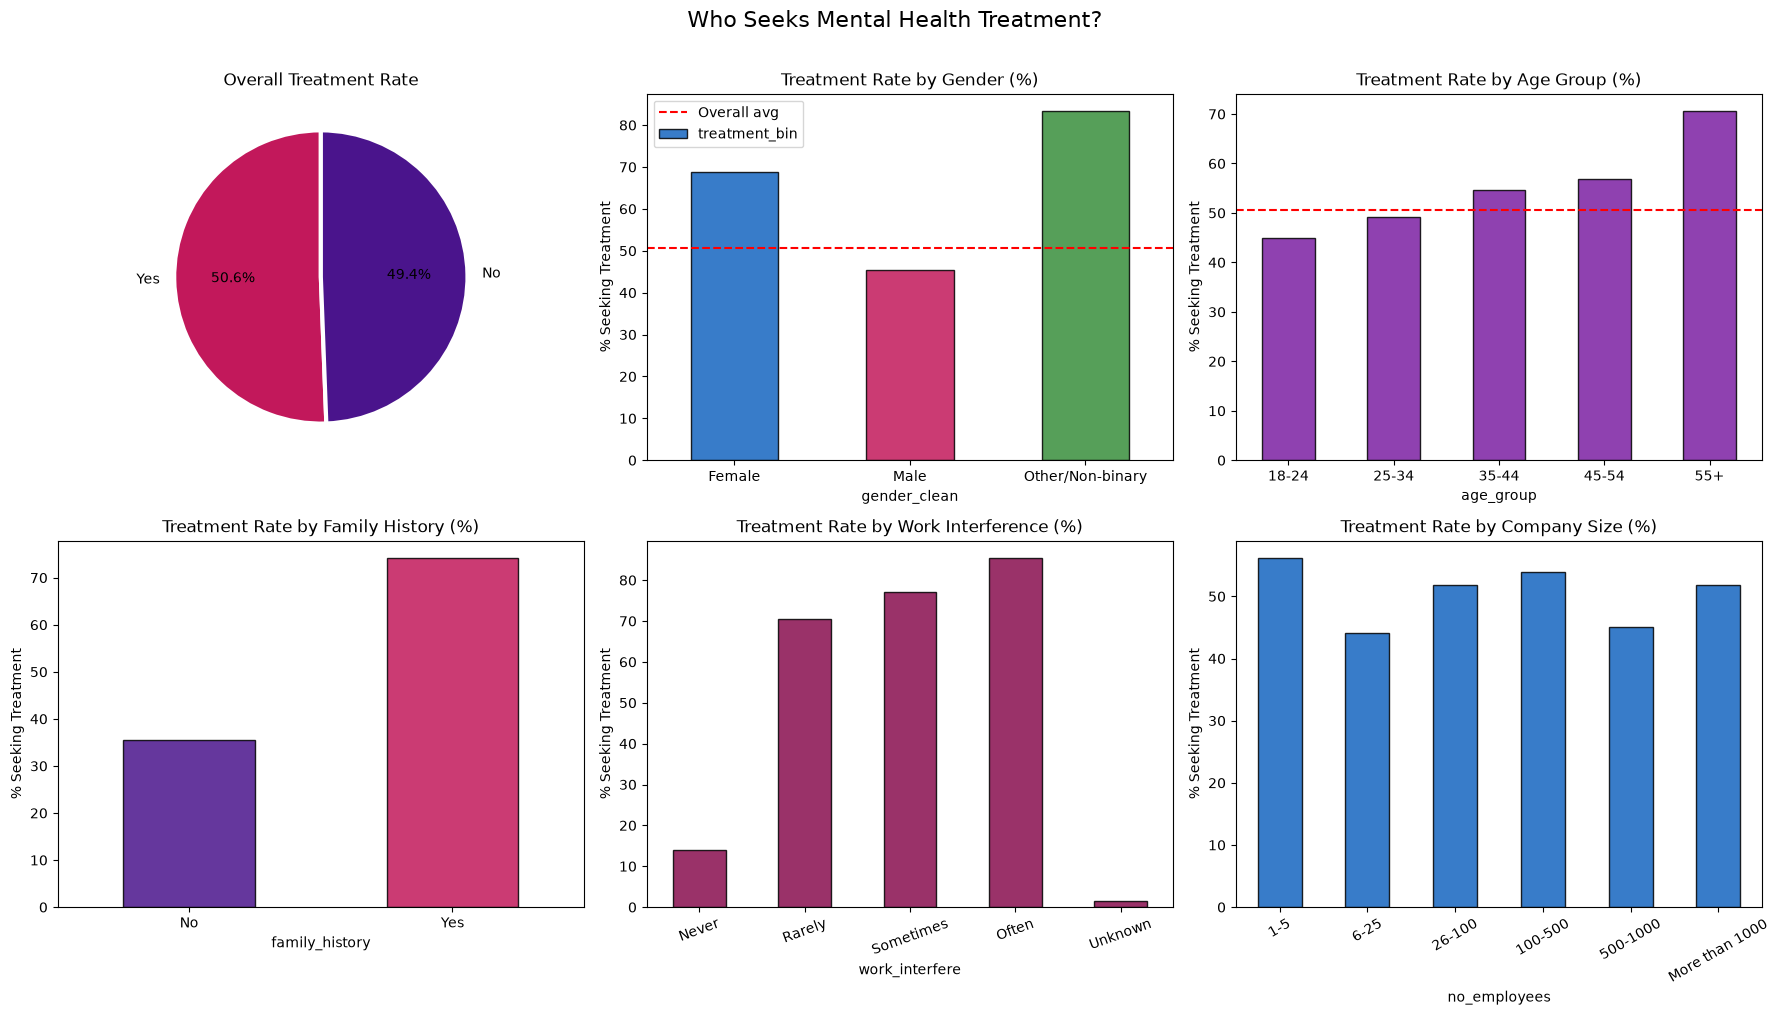

In [57]:
treat_counts = df['treatment'].value_counts()
print(f'Treatment rate: {treat_counts["Yes"]:,} / {len(df):,} = {treat_counts["Yes"]/len(df)*100:.1f}%')

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Overall pie
axes[0,0].pie(treat_counts.values, labels=treat_counts.index,
              colors=['#c2185b','#4a148c'], autopct='%1.1f%%', startangle=90,
              wedgeprops=dict(edgecolor='white', linewidth=3))
axes[0,0].set_title('Overall Treatment Rate')

# By gender
treat_gender = df.groupby('gender_clean')['treatment_bin'].mean() * 100
treat_gender.plot.bar(ax=axes[0,1], color=['#1565c0','#c2185b','#388e3c'],
                      edgecolor='black', alpha=0.85)
axes[0,1].set_title('Treatment Rate by Gender (%)')
axes[0,1].set_ylabel('% Seeking Treatment'); axes[0,1].tick_params(axis='x', rotation=0)
axes[0,1].axhline(df['treatment_bin'].mean()*100, color='red', linestyle='--', lw=1.5, label='Overall avg')
axes[0,1].legend()

# By age group
treat_age = df.groupby('age_group')['treatment_bin'].mean().reindex(['18-24','25-34','35-44','45-54','55+']) * 100
treat_age.plot.bar(ax=axes[0,2], color='#7b1fa2', edgecolor='black', alpha=0.85)
axes[0,2].set_title('Treatment Rate by Age Group (%)')
axes[0,2].set_ylabel('% Seeking Treatment'); axes[0,2].tick_params(axis='x', rotation=0)
axes[0,2].axhline(df['treatment_bin'].mean()*100, color='red', linestyle='--', lw=1.5)

# By family history
treat_fam = df.groupby('family_history')['treatment_bin'].mean() * 100
treat_fam.plot.bar(ax=axes[1,0], color=['#4a148c','#c2185b'], edgecolor='black', alpha=0.85)
axes[1,0].set_title('Treatment Rate by Family History (%)')
axes[1,0].set_ylabel('% Seeking Treatment'); axes[1,0].tick_params(axis='x', rotation=0)

# By work interference
treat_wi = df.groupby('work_interfere')['treatment_bin'].mean() * 100
treat_wi = treat_wi.reindex(['Never','Rarely','Sometimes','Often','Unknown'])
treat_wi.plot.bar(ax=axes[1,1], color='#880e4f', edgecolor='black', alpha=0.85)
axes[1,1].set_title('Treatment Rate by Work Interference (%)')
axes[1,1].set_ylabel('% Seeking Treatment'); axes[1,1].tick_params(axis='x', rotation=20)

# By company size
treat_size = df.groupby('no_employees')['treatment_bin'].mean().reindex(size_order) * 100
treat_size.plot.bar(ax=axes[1,2], color='#1565c0', edgecolor='black', alpha=0.85)
axes[1,2].set_title('Treatment Rate by Company Size (%)')
axes[1,2].set_ylabel('% Seeking Treatment'); axes[1,2].tick_params(axis='x', rotation=30)

plt.suptitle('Who Seeks Mental Health Treatment?', fontsize=16, y=1.01)
plt.tight_layout(); plt.show()


## Feature selection

Build classification models for workplace stress prediction.
First, we deeply analyse the work_interfere variable — our proxy for workplace stress.

In [59]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay,
                              roc_auc_score, roc_curve, f1_score,
                              precision_score, recall_score)


ML dataset: (1259, 25)
Class balance: {1: 637, 0: 622}
Treatment rate: 50.6%


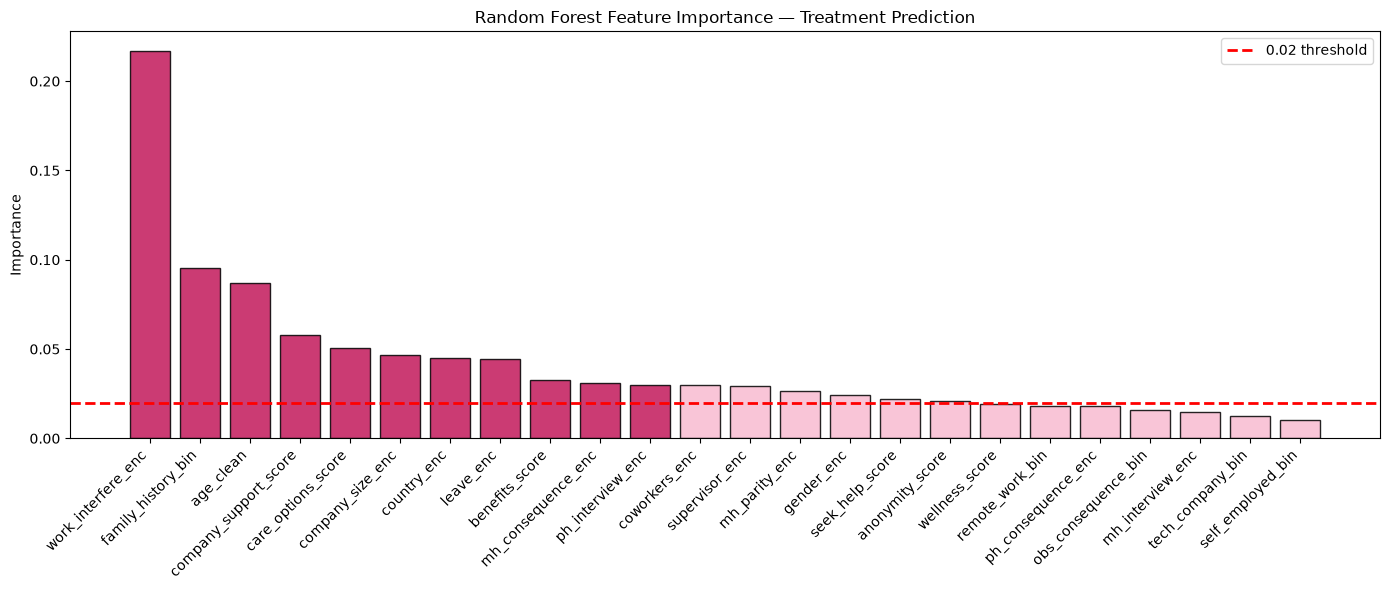


Selected 17 features (importance >= 0.02):
['work_interfere_enc', 'family_history_bin', 'age_clean', 'company_support_score', 'care_options_score', 'company_size_enc', 'country_enc', 'leave_enc', 'benefits_score', 'mh_consequence_enc', 'ph_interview_enc', 'coworkers_enc', 'supervisor_enc', 'mh_parity_enc', 'gender_enc', 'seek_help_score', 'anonymity_score']


In [60]:
FEATURE_COLS = [
    'age_clean','gender_enc','family_history_bin','remote_work_bin',
    'tech_company_bin','self_employed_bin','work_interfere_enc',
    'company_support_score','benefits_score','care_options_score',
    'wellness_score','seek_help_score','anonymity_score',
    'leave_enc','mh_consequence_enc','ph_consequence_enc',
    'coworkers_enc','supervisor_enc','mh_interview_enc',
    'ph_interview_enc','mh_parity_enc','obs_consequence_bin',
    'company_size_enc','country_enc',
]
TARGET = 'treatment_bin'

df_ml = df[FEATURE_COLS + [TARGET]].dropna().copy()
X = df_ml[FEATURE_COLS]; y = df_ml[TARGET]

print(f'ML dataset: {df_ml.shape}')
print(f'Class balance: {y.value_counts().to_dict()}')
print(f'Treatment rate: {y.mean()*100:.1f}%')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Feature importance via Random Forest
rf_sel = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_sel.fit(X_train, y_train)

feat_imp = pd.DataFrame({'Feature': FEATURE_COLS, 'Importance': rf_sel.feature_importances_}
                        ).sort_values('Importance', ascending=False)

plt.figure(figsize=(14, 6))
colors_fi = ['#c2185b' if v > 0.03 else '#f8bbd0' for v in feat_imp['Importance']]
plt.bar(feat_imp['Feature'], feat_imp['Importance'], color=colors_fi, edgecolor='black', alpha=0.85)
plt.axhline(0.02, color='red', linestyle='--', lw=2, label='0.02 threshold')
plt.title('Random Forest Feature Importance — Treatment Prediction')
plt.ylabel('Importance'); plt.xticks(rotation=45, ha='right'); plt.legend()
plt.tight_layout(); plt.show()

TOP_FEATURES = feat_imp[feat_imp['Importance'] >= 0.02]['Feature'].tolist()
print(f'\nSelected {len(TOP_FEATURES)} features (importance >= 0.02):')
print(TOP_FEATURES)


### ML — Classification Models

We train 5 classification models to predict whether an employee will seek mental health treatment.
Metric focus: F1-score and ROC-AUC — because we care about both precision and recall for mental health prediction.

In [62]:
try:
    import xgboost as xgb
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False

In [ ]:
#import xgboost as xgb

In [61]:
# ============================================================
# SECTION 13 — Classification Models
# ============================================================
X_sel = df_ml[TOP_FEATURES]
X_tr, X_te, y_tr, y_te = train_test_split(X_sel, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

cls_results = {}

def eval_cls(name, y_true, y_pred, y_prob=None):
    acc  = accuracy_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred, average='weighted')
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    auc  = roc_auc_score(y_true, y_prob) if y_prob is not None else 0.0
    print(f'  {name}: Acc={acc:.4f} F1={f1:.4f} AUC={auc:.4f}')
    cls_results[name] = {'Accuracy': round(acc,4), 'F1': round(f1,4),
                          'Precision': round(prec,4), 'Recall': round(rec,4), 'AUC': round(auc,4)}
    return y_pred, y_prob

print('='*65)
print('CLASSIFICATION MODELS — Predicting Treatment Seeking')
print('='*65)

# 1. Logistic Regression
lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr.fit(X_tr_s, y_tr)
lr_pred, lr_prob = eval_cls('Logistic Regression', y_te, lr.predict(X_te_s), lr.predict_proba(X_te_s)[:,1])

# 2. Decision Tree
dt = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42)
dt.fit(X_tr, y_tr)
dt_pred, dt_prob = eval_cls('Decision Tree', y_te, dt.predict(X_te), dt.predict_proba(X_te)[:,1])

# 3. Random Forest
rf = RandomForestClassifier(n_estimators=300, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
rf_pred, rf_prob = eval_cls('Random Forest', y_te, rf.predict(X_te), rf.predict_proba(X_te)[:,1])

# 4. Gradient Boosting
gbm = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42)
gbm.fit(X_tr, y_tr)
gbm_pred, gbm_prob = eval_cls('Gradient Boosting', y_te, gbm.predict(X_te), gbm.predict_proba(X_te)[:,1])

# 5. XGBoost
if XGB_AVAILABLE:
    xgb_model = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                    subsample=0.8, eval_metric='logloss', random_state=42, verbosity=0)
    xgb_model.fit(X_tr, y_tr)
    xgb_pred, xgb_prob = eval_cls('XGBoost', y_te, xgb_model.predict(X_te), xgb_model.predict_proba(X_te)[:,1])
else:
    xgb_pred, xgb_prob = gbm_pred, gbm_prob
    print('  (XGBoost not available — using GBM)')

CLASSIFICATION MODELS — Predicting Treatment Seeking
  Logistic Regression: Acc=0.7659 F1=0.7659 AUC=0.8550
  Decision Tree: Acc=0.7619 F1=0.7617 AUC=0.8250
  Random Forest: Acc=0.7897 F1=0.7896 AUC=0.8533
  Gradient Boosting: Acc=0.7698 F1=0.7699 AUC=0.8458


NameError: name 'XGB_AVAILABLE' is not defined